In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import AUDIO_FEATURES
from data import load_data, clean_data

df = load_data()
df_clean = clean_data(df)

2026-10-29 10:43:42.141 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:43:42.143 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:43:42.145 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:43:42.146 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 10:43:43.822 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 10:43:43.878 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [2]:
# 🎓 Projet Machine Learning n°2 — Spotify : décrypter la musique 🎧
# 1. **Structure** : dimensions, types, valeurs manquantes.
print("Dimensions :", df.shape)

df.info()

print(df.isnull().sum())

df.describe()

Dimensions : (32833, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [ ]:
# =========================================================
# 2. DOUBLONS
# =========================================================
print("Nombre de lignes :", len(df))
print("Morceaux uniques :", df["track_id"].nunique())

nb_genres = df.groupby("track_id")["playlist_genre"].nunique()

print("Morceaux avec plusieurs genres :", (nb_genres > 1).sum())

Nombre de lignes : 32833
Morceaux uniques : 28356
Morceaux avec plusieurs genres : 1687


Le dataset initial contient 32 833 lignes, mais seulement 28 356 morceaux uniques identifiés par leur track_id. Cette différence s'explique par la présence de morceaux dans plusieurs playlists. Parmi ces morceaux, 1 687 sont associés à plusieurs genres musicaux. Lors du nettoyage, nous conservons une seule occurrence par identifiant, mais cela implique de ne retenir qu'un seul genre pour certains morceaux.

In [ ]:
# =========================================================
# 3. Changements de types et nouvelles variables
# =========================================================

print(df_clean[["release_year", "duration_min", "playlist_genre"]].head())

print(df_clean.dtypes)

print("Doublons restants :", df_clean["track_id"].duplicated().sum())

       release_year  duration_min playlist_genre
1551           2019      3.490633            pop
20092          2019      2.727267          latin
687            2019      3.349333            pop
711            2019      3.158100            pop
716            2019      3.359550            pop
track_id                      object
track_name                    object
track_artist                  object
track_popularity               int64
track_album_id                object
track_album_name              object
track_album_release_date      object
playlist_name                 object
playlist_id                   object
playlist_genre              category
playlist_subgenre             object
danceability                 float64
energy                       float64
key                            int64
loudness                     float64
mode                           int64
speechiness                  float64
acousticness                 float64
instrumentalness             float64
liv

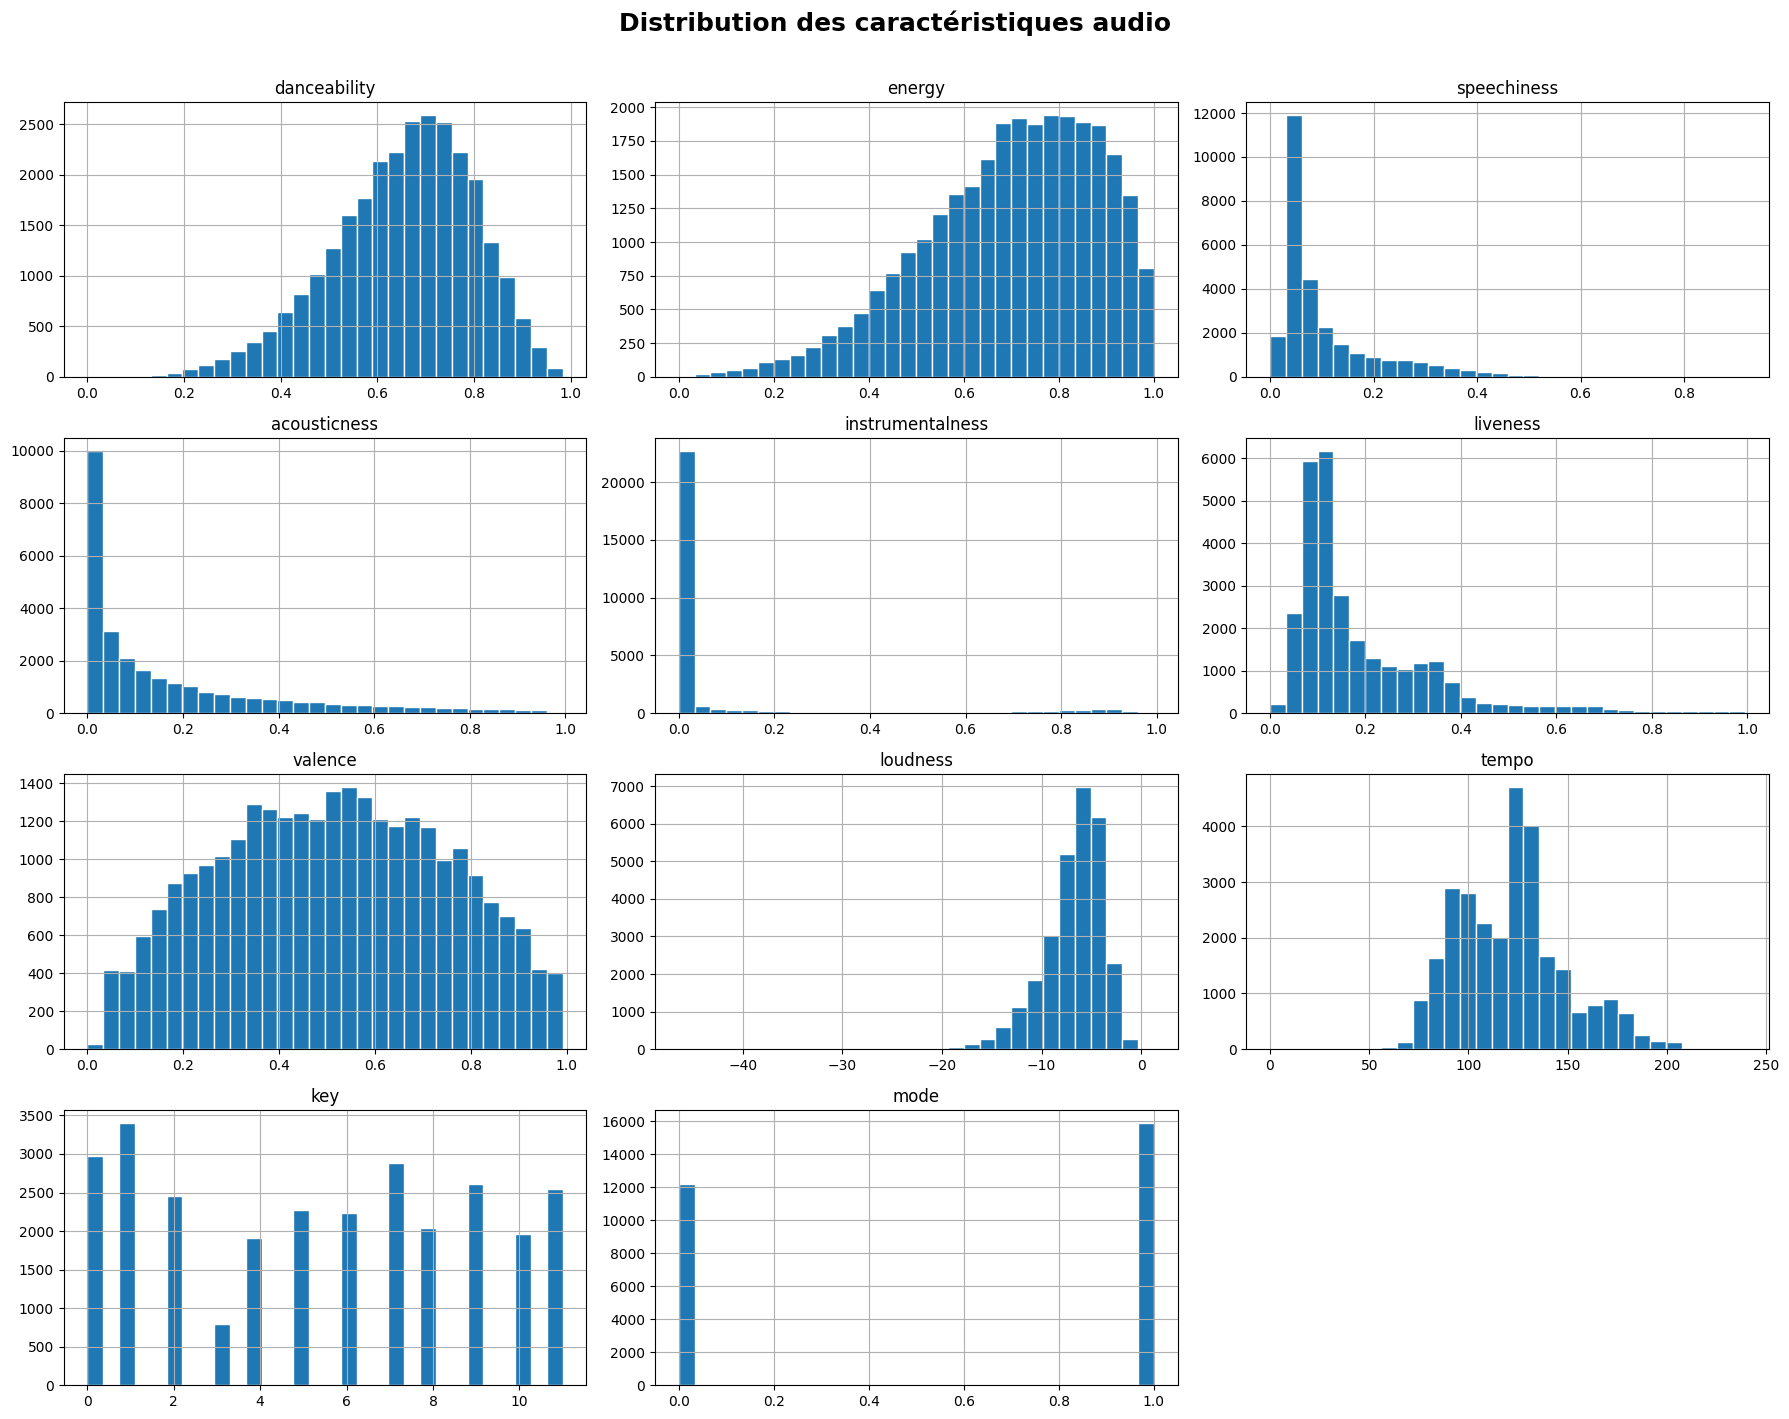

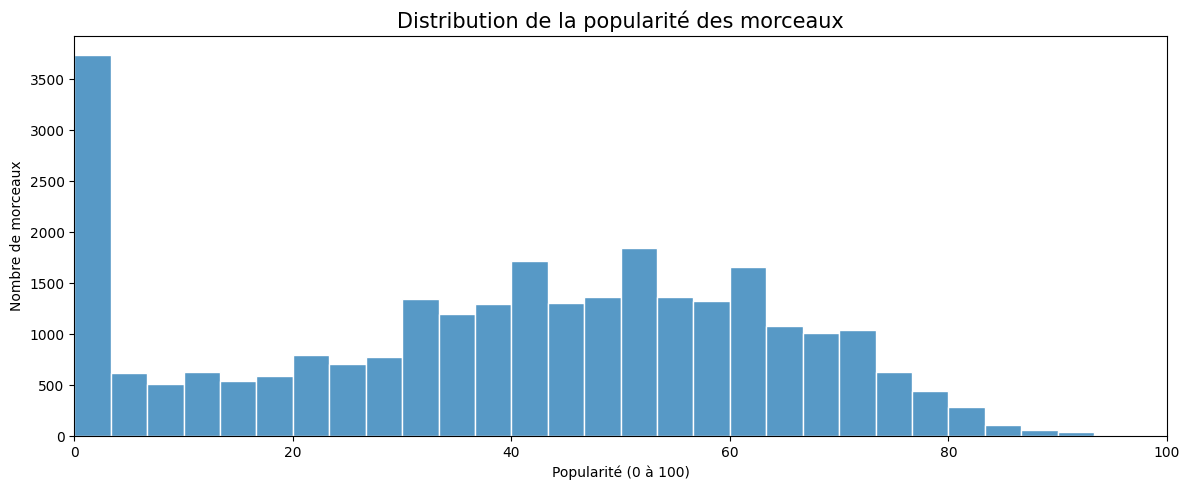

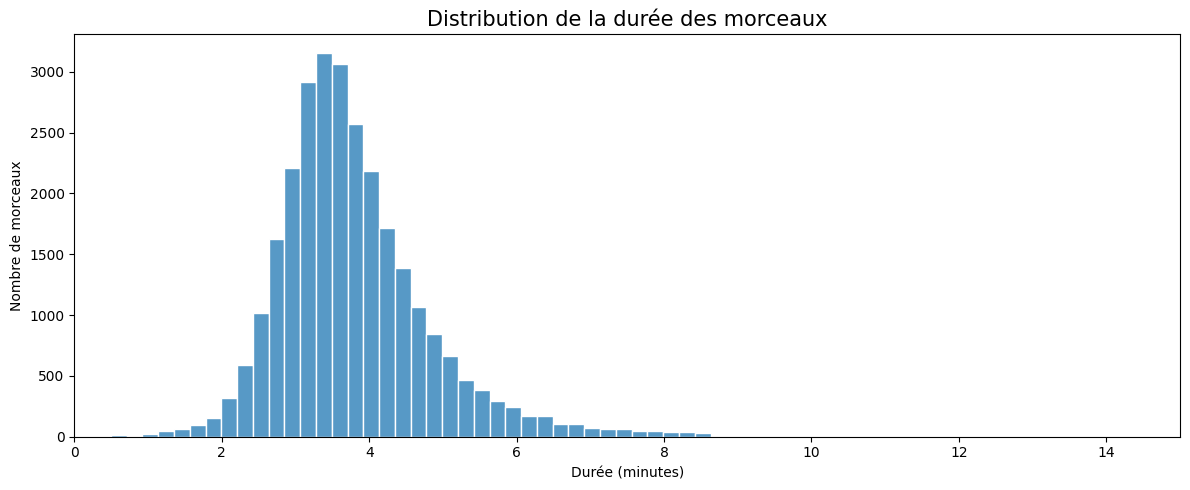

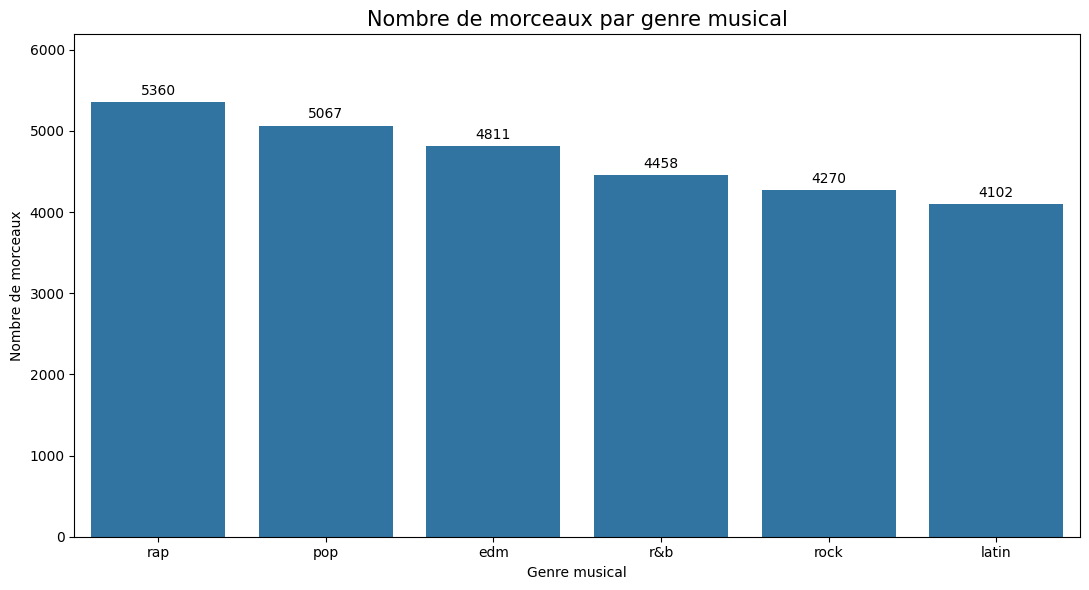

Nombre de morceaux par genre :
playlist_genre
rap      5360
pop      5067
edm      4811
r&b      4458
rock     4270
latin    4102
Name: count, dtype: int64


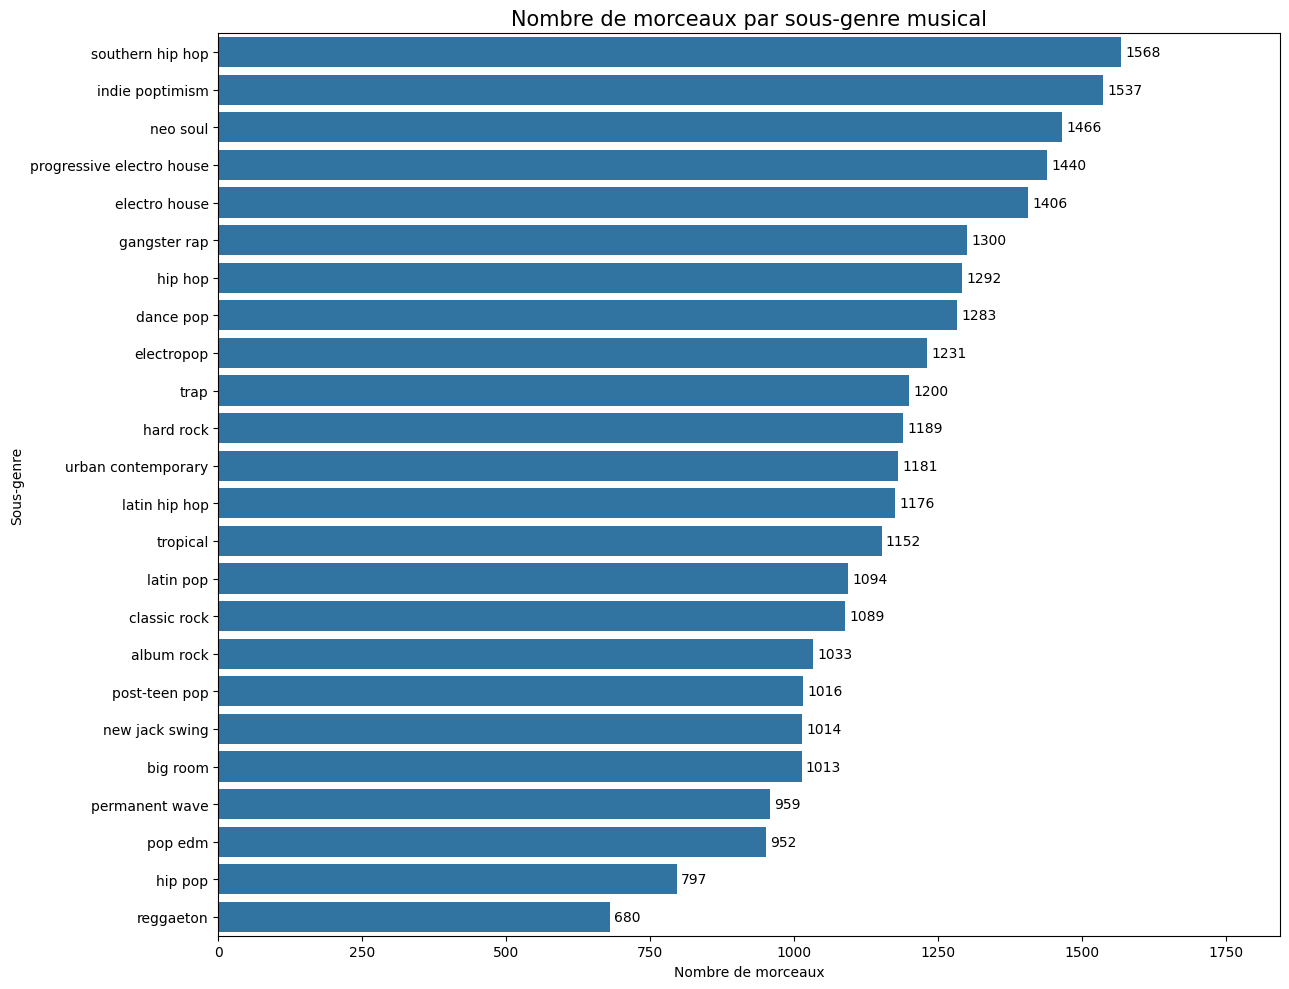

In [6]:
# =========================================================
# 4. ANALYSE UNIVARIÉE
# =========================================================

# 4.1 Distribution des caractéristiques audio

df_clean[AUDIO_FEATURES].hist(
    figsize=(18, 14),
    bins=30,
    layout=(4, 3),
    edgecolor="white"
)

plt.suptitle(
    "Distribution des caractéristiques audio",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


# =========================================================
# 4.2 Distribution de la popularité
# =========================================================

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_clean,
    x="track_popularity",
    bins=30,
    edgecolor="white"
)

plt.title("Distribution de la popularité des morceaux", fontsize=15)
plt.xlabel("Popularité (0 à 100)")
plt.ylabel("Nombre de morceaux")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


# =========================================================
# 4.3 Distribution de la durée
# =========================================================

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_clean,
    x="duration_min",
    bins=40,
    edgecolor="white"
)

plt.title("Distribution de la durée des morceaux", fontsize=15)
plt.xlabel("Durée (minutes)")
plt.ylabel("Nombre de morceaux")
plt.xlim(0, 15)
plt.tight_layout()
plt.show()


# =========================================================
# 4.4 Nombre de morceaux par genre
# =========================================================

ordre_genres = df_clean["playlist_genre"].value_counts().index

plt.figure(figsize=(11, 6))

ax = sns.countplot(
    data=df_clean,
    x="playlist_genre",
    order=ordre_genres
)

plt.title("Nombre de morceaux par genre musical", fontsize=15)
plt.xlabel("Genre musical")
plt.ylabel("Nombre de morceaux")

# Afficher les valeurs sur les barres
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.ylim(0, ax.get_ylim()[1] * 1.1)
plt.tight_layout()
plt.show()

print("Nombre de morceaux par genre :")
print(df_clean["playlist_genre"].value_counts())


# =========================================================
# 4.5 Nombre de morceaux par sous-genre
# =========================================================

ordre_sous_genres = df_clean["playlist_subgenre"].value_counts().index

plt.figure(figsize=(13, 10))

ax = sns.countplot(
    data=df_clean,
    y="playlist_subgenre",
    order=ordre_sous_genres
)

plt.title("Nombre de morceaux par sous-genre musical", fontsize=15)
plt.xlabel("Nombre de morceaux")
plt.ylabel("Sous-genre")

# Afficher les valeurs au bout des barres
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.xlim(0, ax.get_xlim()[1] * 1.12)
plt.tight_layout()
plt.show()

Caractéristiques audio :

Les morceaux Spotify présentent généralement une énergie (energy) et une capacité à danser (danceability) assez élevées. En revanche, les valeurs de speechiness, acousticness et instrumentalness sont souvent proches de zéro.

Le tempo (tempo) se situe principalement entre 90 et 140 BPM. La variable valence, qui représente le caractère positif d'une musique, est assez bien répartie entre 0 et 1.

Popularité :

La popularité des morceaux se concentre principalement entre 30 et 70. On observe également un nombre important de morceaux ayant une popularité égale à zéro.

Il serait intéressant de vérifier pourquoi autant de morceaux ont cette valeur. Le graphique seul ne permet pas de savoir s'il s'agit réellement de morceaux peu populaires ou de valeurs particulières du dataset.

10:00 : MOdification du fichier data.py pour supprimer les doublon en fonction du titre/artiste/album et garder celui avec la meilleur pop

Nous avons identifié plusieurs morceaux avec des identifiants Spotify différents mais des informations similaires. Nous avons donc adapté le nettoyage pour conserver la version la plus populaire lorsque les caractéristiques audio sont identiques.

Après nettoyage, nous conservons 28 068 morceaux sur 32 833 lignes initiales. Aucun doublon ne subsiste selon les critères retenus. Les versions présentant des caractéristiques audio différentes sont conservées afin de ne pas perdre d'informations utiles pour les modèles.

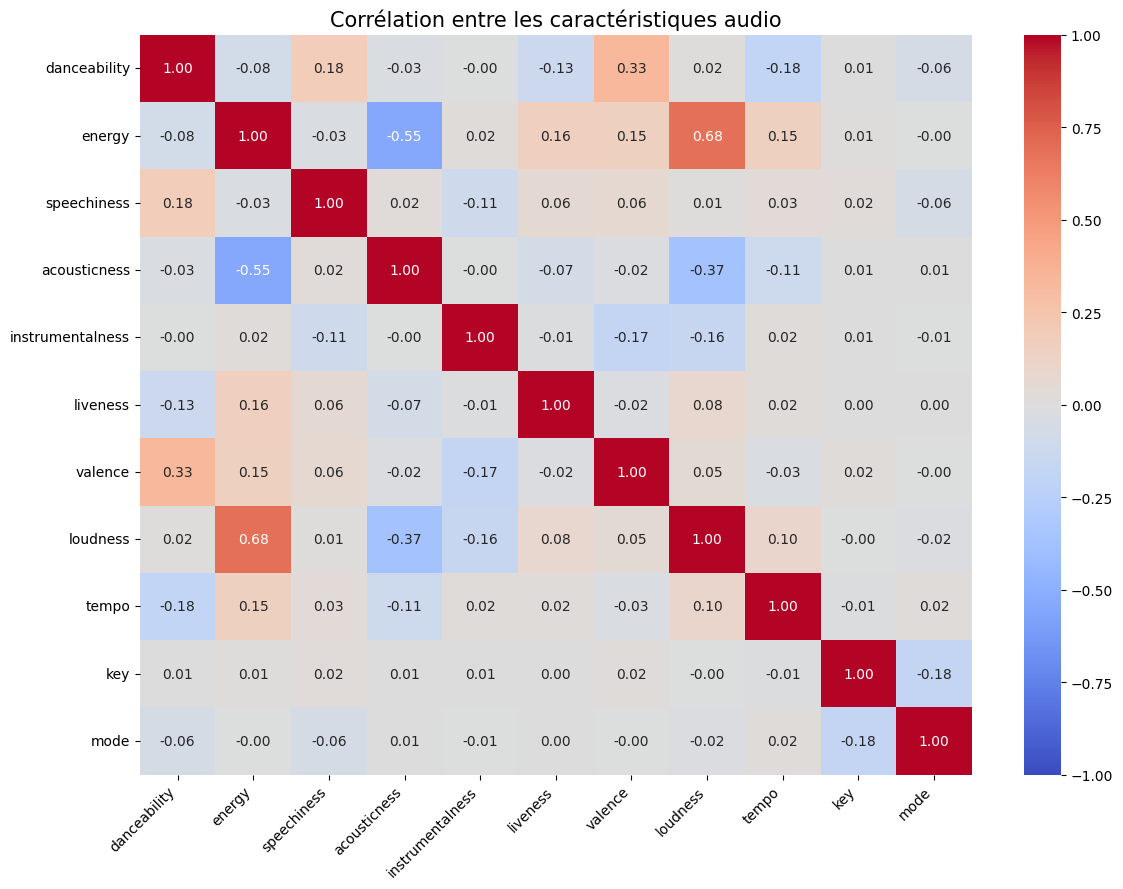

Corrélations avec energy :
energy              1.000000
loudness            0.682003
liveness            0.163587
valence             0.151353
tempo               0.150651
instrumentalness    0.021464
key                 0.012452
mode               -0.004159
speechiness        -0.027999
danceability       -0.080766
acousticness       -0.546733
Name: energy, dtype: float64


In [7]:
# =========================================================
# 5. Analyse Bivariée
# =========================================================


# =========================================================
# 5.1 Matrice de corrélation
# =========================================================

correlation = df_clean[AUDIO_FEATURES].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Corrélation entre les caractéristiques audio", fontsize=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Corrélations avec energy :")
print(correlation["energy"].sort_values(ascending=False))

Loudness (+0,68) : plus un morceau est fort en volume sonore, plus son énergie a tendance à être élevée.

Acousticness (−0,55) : les morceaux ayant une forte composante acoustique ont généralement une énergie plus faible.

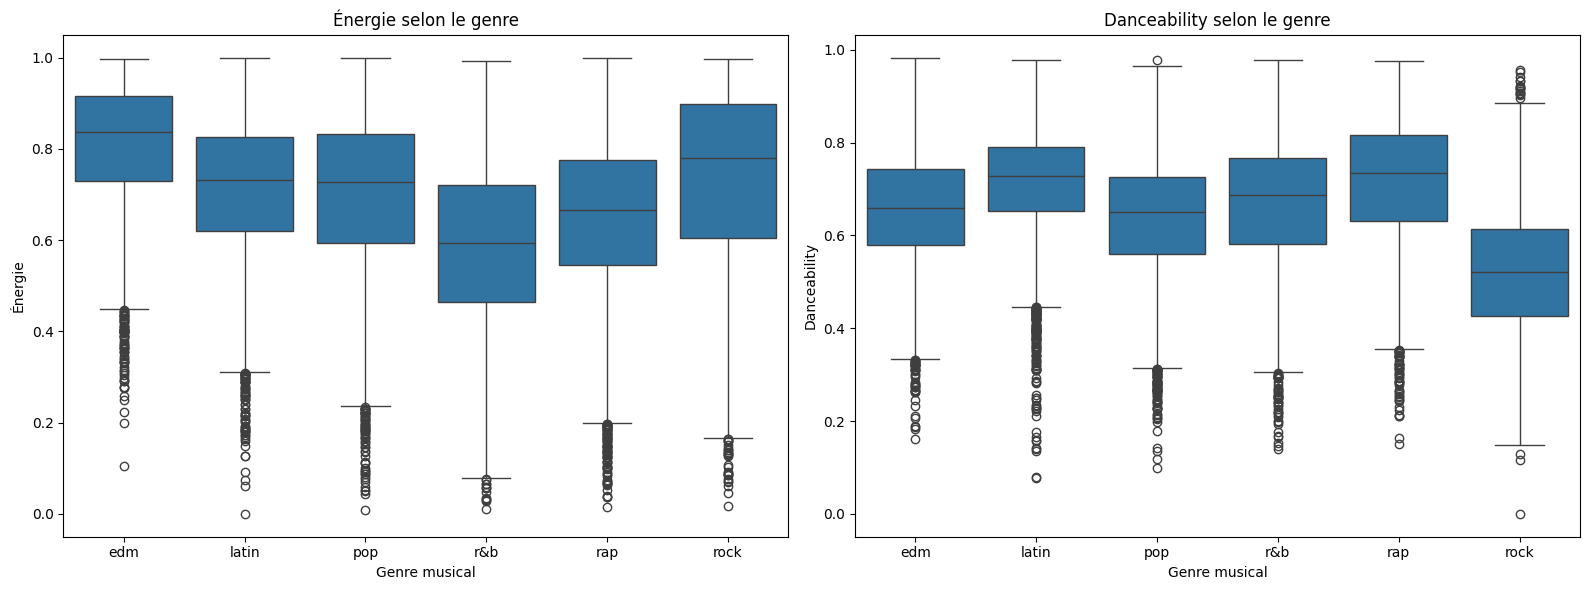

In [8]:
# =========================================================
# 5.2 Boxplots des caractéristiques audio par genre
# =========================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=df_clean,
    x="playlist_genre",
    y="energy",
    ax=axes[0]
)

axes[0].set_title("Énergie selon le genre")
axes[0].set_xlabel("Genre musical")
axes[0].set_ylabel("Énergie")

sns.boxplot(
    data=df_clean,
    x="playlist_genre",
    y="danceability",
    ax=axes[1]
)

axes[1].set_title("Danceability selon le genre")
axes[1].set_xlabel("Genre musical")
axes[1].set_ylabel("Danceability")

plt.tight_layout()
plt.show()

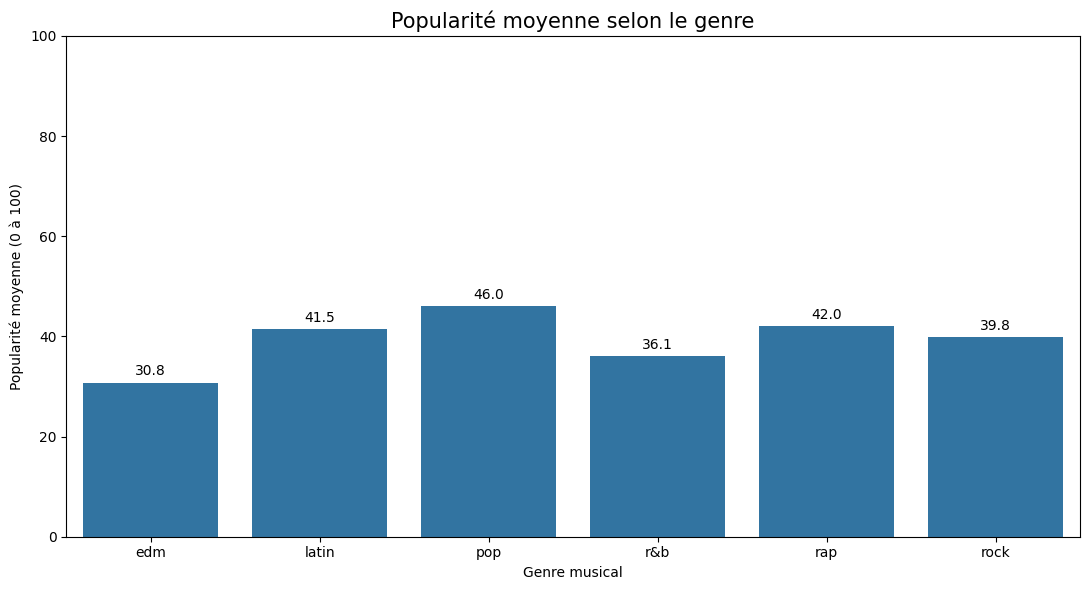

playlist_genre
pop      46.03
rap      42.05
latin    41.51
rock     39.84
r&b      36.13
edm      30.79
Name: track_popularity, dtype: float64


In [9]:
# =========================================================
# 5.3 Popularité moyenne par genre
# =========================================================

popularite_genre = (
    df_clean.groupby("playlist_genre", observed=True)["track_popularity"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=popularite_genre.index,
    y=popularite_genre.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.title("Popularité moyenne selon le genre", fontsize=15)
plt.xlabel("Genre musical")
plt.ylabel("Popularité moyenne (0 à 100)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(popularite_genre.round(2))

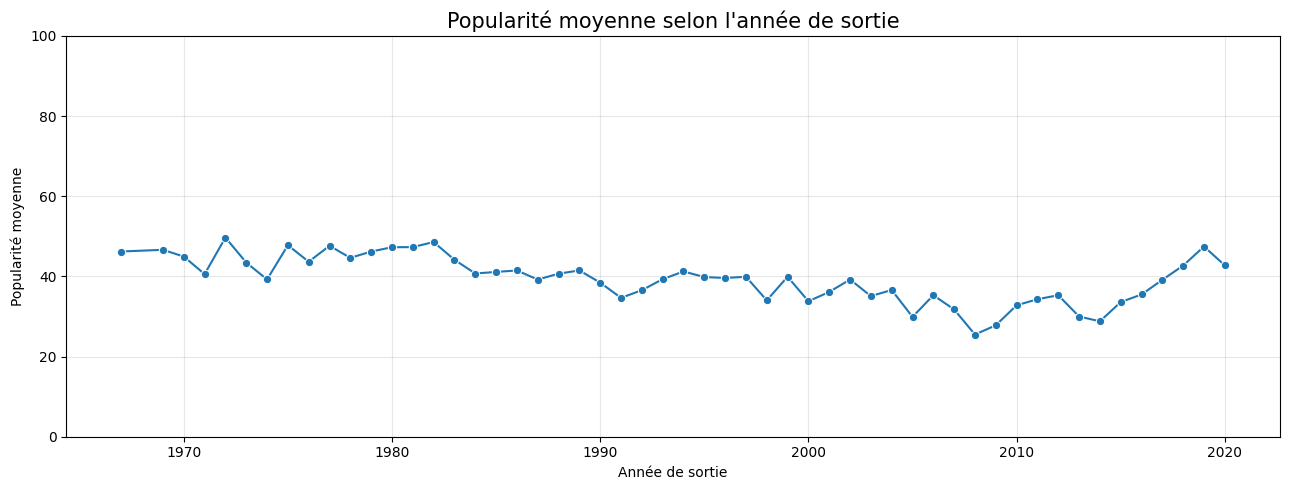

In [10]:
# =========================================================
# 5.4 Popularité selon l'année de sortie
# =========================================================

popularite_annee = df_clean.groupby("release_year").agg(
    popularite_moyenne=("track_popularity", "mean"),
    nombre_morceaux=("track_id", "size")
)

# Conserver les années avec au moins 30 morceaux
popularite_annee = popularite_annee[
    popularite_annee["nombre_morceaux"] >= 30
]

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=popularite_annee,
    x=popularite_annee.index,
    y="popularite_moyenne",
    marker="o"
)

plt.title("Popularité moyenne selon l'année de sortie", fontsize=15)
plt.xlabel("Année de sortie")
plt.ylabel("Popularité moyenne")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

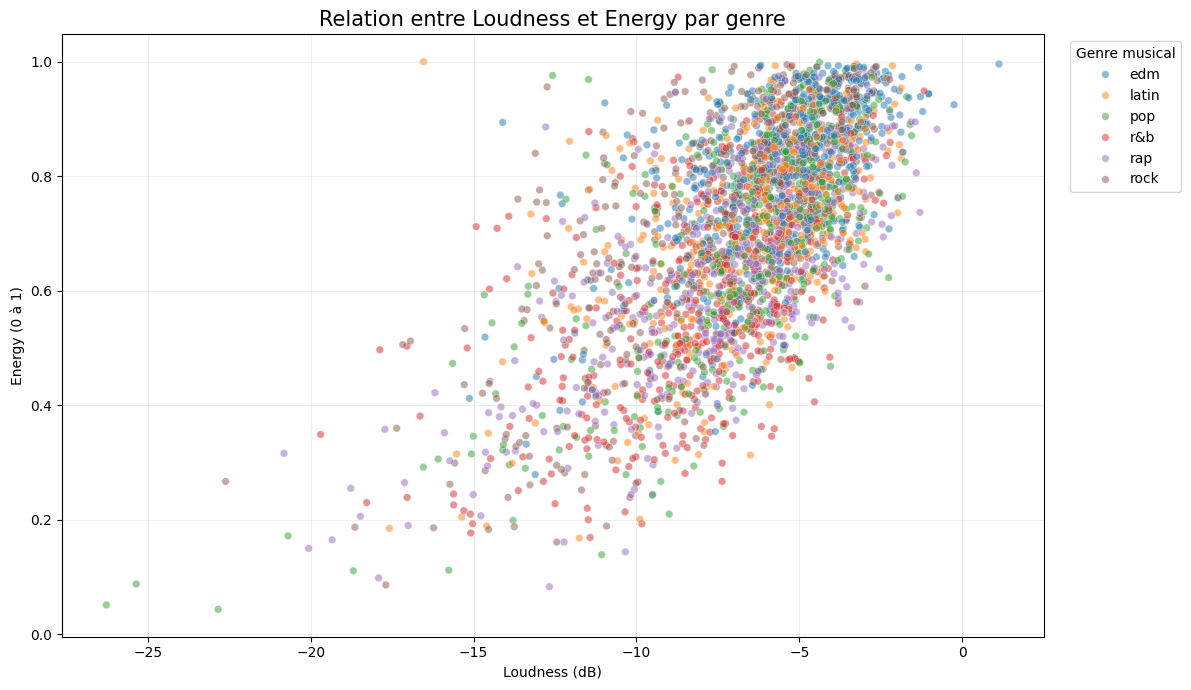

In [11]:
# =========================================================
# 5.5 Relation Loudness / Energy selon le genre
# =========================================================

# Échantillon pour rendre le graphique plus lisible
echantillon = df_clean.sample(
    n=min(3000, len(df_clean)),
    random_state=42
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=echantillon,
    x="loudness",
    y="energy",
    hue="playlist_genre",
    alpha=0.5,
    s=30
)

plt.title("Relation entre Loudness et Energy par genre", fontsize=15)
plt.xlabel("Loudness (dB)")
plt.ylabel("Energy (0 à 1)")
plt.legend(title="Genre musical", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

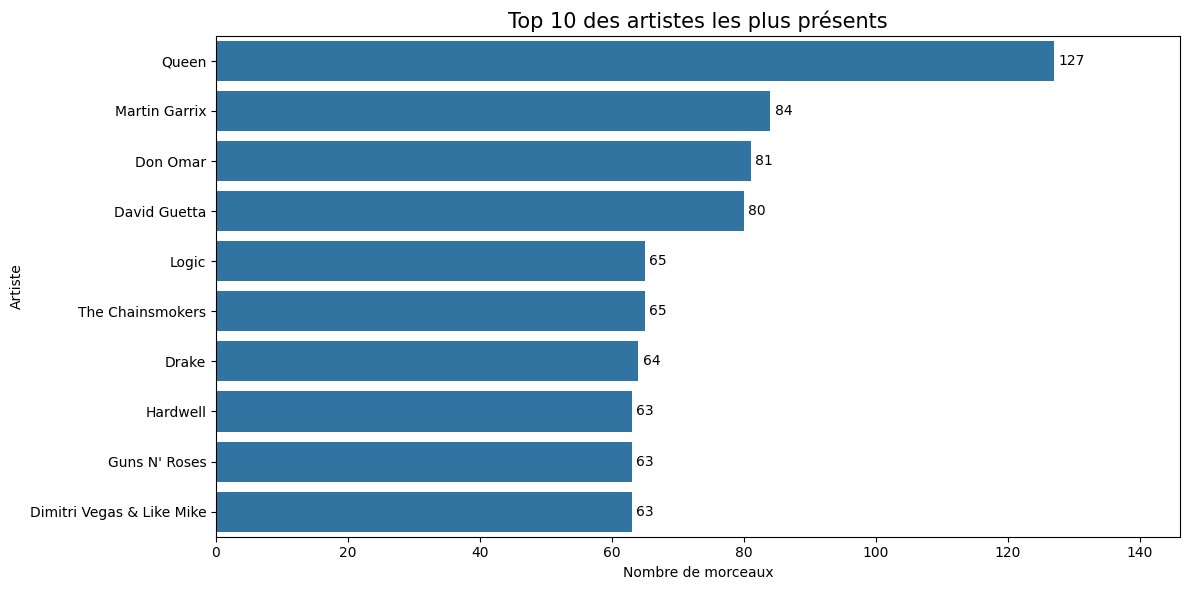

Top 10 des artistes :
track_artist
Queen                        127
Martin Garrix                 84
Don Omar                      81
David Guetta                  80
Logic                         65
The Chainsmokers              65
Drake                         64
Hardwell                      63
Guns N' Roses                 63
Dimitri Vegas & Like Mike     63
Name: count, dtype: int64


In [12]:
# =========================================================
# 6. Artistes et morceaux les plus populaires
# =========================================================


# =========================================================
# 6.1 Top 10 des artistes les plus représentés
# =========================================================
top_artistes = df_clean["track_artist"].value_counts().head(10)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_artistes.values,
    y=top_artistes.index
)

plt.title("Top 10 des artistes les plus présents", fontsize=15)
plt.xlabel("Nombre de morceaux")
plt.ylabel("Artiste")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.xlim(0, top_artistes.max() * 1.15)
plt.tight_layout()
plt.show()

print("Top 10 des artistes :")
print(top_artistes)

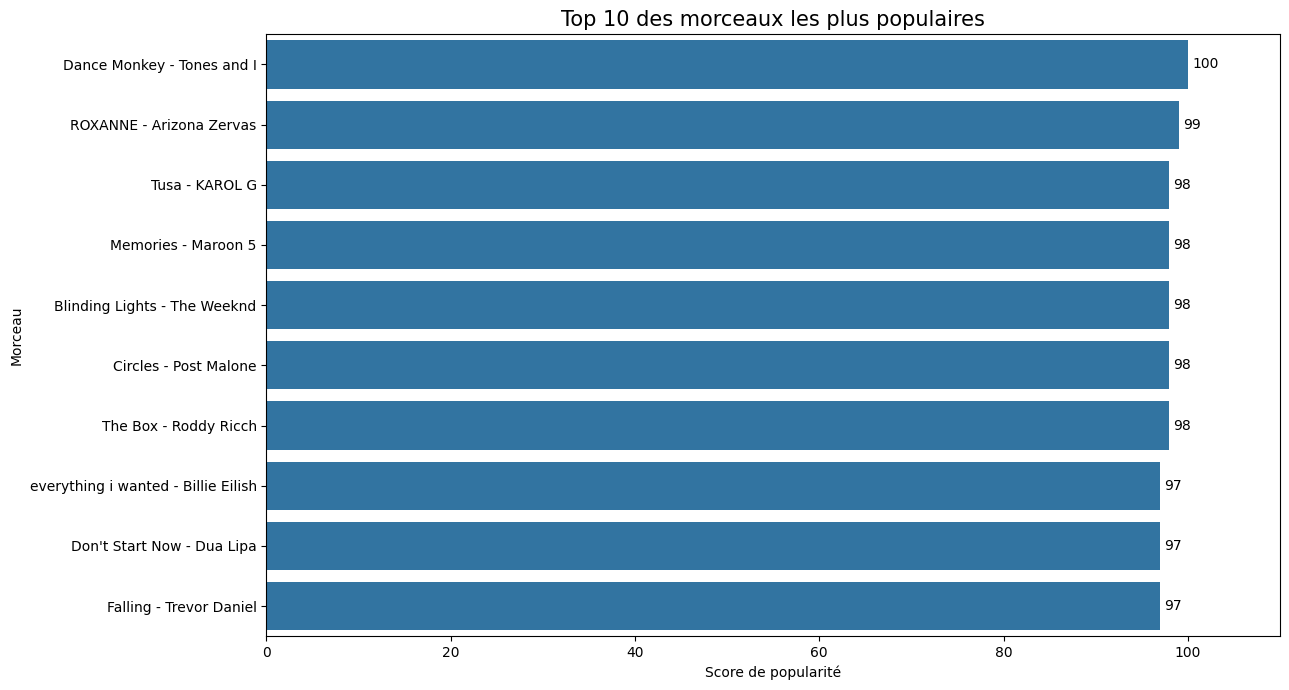

Top 10 des morceaux les plus populaires :


,track_name,track_artist,track_album_name,release_year,track_popularity
1551,Dance Monkey,Tones and I,Dance Monkey (Stripped Back) / Dance Monkey,2019,100
20092,ROXANNE,Arizona Zervas,ROXANNE,2019,99
687,Tusa,KAROL G,Tusa,2019,98
711,Memories,Maroon 5,Memories,2019,98
716,Blinding Lights,The Weeknd,Blinding Lights,2019,98
1301,Circles,Post Malone,Hollywood's Bleeding,2019,98
5508,The Box,Roddy Ricch,Please Excuse Me For Being Antisocial,2019,98
689,everything i wanted,Billie Eilish,everything i wanted,2019,97
1302,Don't Start Now,Dua Lipa,Don't Start Now,2019,97
3155,Falling,Trevor Daniel,Falling,2018,97


In [ ]:
# =========================================================
# 6.2 Top 10 des morceaux les plus populaires
# =========================================================

top_morceaux = (
    df_clean
    .sort_values("track_popularity", ascending=False, kind="stable")
    .drop_duplicates(subset=["track_artist", "track_name"])
    .head(10)
    .copy()
)

top_morceaux["morceau"] = (
    top_morceaux["track_name"].str.slice(0, 35)
    + " - "
    + top_morceaux["track_artist"].str.slice(0, 20)
)

plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=top_morceaux,
    x="track_popularity",
    y="morceau"
)

plt.title("Top 10 des morceaux les plus populaires", fontsize=15)
plt.xlabel("Score de popularité")
plt.ylabel("Morceau")
plt.xlim(0, 110)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

# Afficher les informations complètes
print("Top 10 des morceaux les plus populaires :")

display(
    top_morceaux[
        ["track_name", "track_artist", "track_album_name",
         "release_year", "track_popularity"]
    ]
)

## 7. Conclusions de l'analyse exploratoire

**1. Présence de doublons**

Le dataset contient initialement 32 833 lignes. Après nettoyage, nous conservons 28 068 morceaux. Nous avons supprimé les doublons en conservant les versions les plus populaires lorsque les identifiants ou les caractéristiques audio permettent de les considérer comme identiques.

**2. Certains morceaux appartiennent à plusieurs genres**

Nous avons identifié 1 687 morceaux associés à plusieurs genres musicaux dans le dataset initial. Cela peut compliquer la classification, car un même morceau peut se retrouver dans différentes playlists.

**3. Des morceaux généralement énergétiques et dansants**

Les distributions montrent que les morceaux possèdent souvent des valeurs assez élevées de `energy` et `danceability`. À l'inverse, `speechiness`, `acousticness` et `instrumentalness` sont généralement faibles.

**4. Une corrélation importante entre le volume et l'énergie**

La variable `loudness` présente une corrélation positive de +0,68 avec `energy`. Les morceaux ayant un volume sonore plus élevé ont donc tendance à être plus énergétiques.

**5. Une relation négative entre acousticness et energy**

La variable `acousticness` présente une corrélation de -0,55 avec `energy`. Les morceaux acoustiques ont généralement une énergie plus faible. Cette variable pourrait donc être intéressante pour la régression.